# GRU at Initialization: DEER vs Broyden variants

A **GRU** (Gated Recurrent Unit) with random initial weights defines a nonlinear
recurrence $x_t = f(x_{t-1}, u_t)$. We solve the trajectory in parallel using DEER
and compare convergence across all solvers.

**Setup** (matching lds_fxd_pts):
- Hidden dimension D = 8
- Sequence length T = 1000
- Initial state: zeros
- Drivers: i.i.d. $\mathcal{N}(0, 1)$
- Initial guess: i.i.d. $\mathcal{N}(0, 1)$

**Goal**: compare Newton iterations to convergence across:
- Sequential rollout (reference)
- DEER, quasi-DEER, Jacobi, Picard
- Broyden-DEER
- Full-Broyden (global Woodbury)
- Accelerated Broyden (fresh diagonal + rank-k secant)

In [9]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [10]:
import jax
import jax.numpy as jnp
import jax.random as jr
import numpy as np
import matplotlib.pyplot as plt

import sys, os
sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()), "src"))

from algs.deer import deer_alg, picard_alg, jacobi_alg, get_residual
from algs.broyden_deer import broyden_deer_alg
from algs.full_broyden import full_broyden_deer_alg
from algs.accelerated_broyden import accelerated_broyden_deer_alg
from dynamics.gru import GRU

## GRU setup

The GRU is an Equinox `GRUCell` with input dimension = hidden dimension = D.
Weights are randomly initialized (not trained).

In [11]:
D    = 128
T    = 1000
seed = 42

key = jr.PRNGKey(seed)
k1, k2, k3, k4 = jr.split(key, 4)

# Build GRU
gru = GRU(D, key=k1, gain=3.)
deer_fxn = gru.deer_fxn

# Initial state, drivers, initial guess
initial_state = jnp.zeros(D)
drivers       = jr.normal(k2, (T, D))
states_guess  = jr.normal(k3, (T, D))

# Sanity check
out = deer_fxn(initial_state, drivers[0])
print(f"D = {D}, T = {T}")
print(f"Output shape: {out.shape}, all finite: {jnp.all(jnp.isfinite(out))}")

D = 128, T = 1000
Output shape: (128,), all finite: True


## Sequential rollout (reference)

Sequential trajectory shape: (1000, 128)


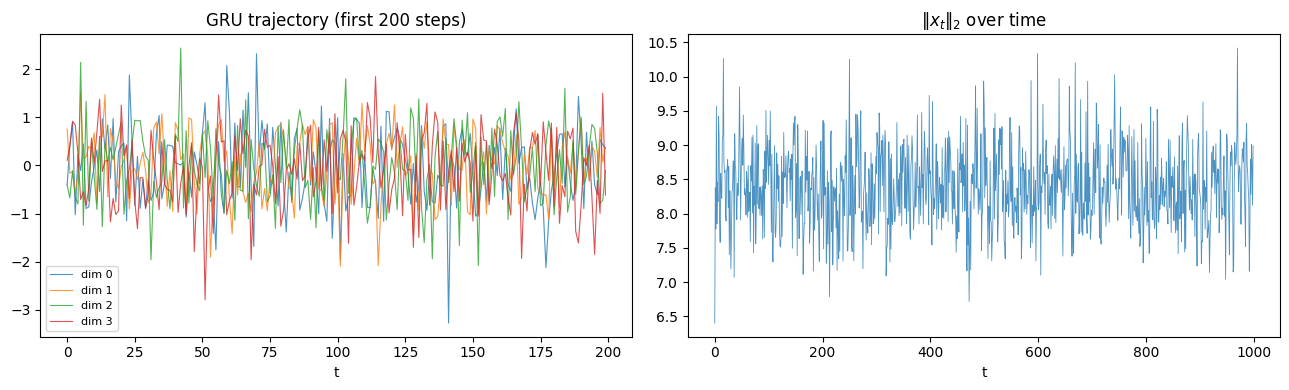

In [12]:
@jax.jit
def run_sequential(init, drivers):
    def step(state, driver):
        new = deer_fxn(state, driver)
        return new, new
    _, trajectory = jax.lax.scan(step, init, drivers)
    return trajectory

seq_trajectory = run_sequential(initial_state, drivers)
print(f"Sequential trajectory shape: {seq_trajectory.shape}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for d in range(min(D, 4)):
    axes[0].plot(seq_trajectory[:200, d], alpha=0.8, linewidth=0.8, label=f'dim {d}')
axes[0].set_title('GRU trajectory (first 200 steps)')
axes[0].set_xlabel('t'); axes[0].legend(fontsize=8)

axes[1].plot(jnp.linalg.norm(seq_trajectory, axis=1), alpha=0.8, linewidth=0.6)
axes[1].set_title(r'$\|x_t\|_2$ over time')
axes[1].set_xlabel('t')
plt.tight_layout()

## Jacobian structure

The GRU Jacobian $\partial f / \partial x_{t-1}$ has gating structure.
Unlike the eight-schools model (rank-2), the GRU Jacobian is generally full-rank.

Spectral radius: 2.0938
Effective rank (>1% of sigma_1): 110
Singular values: [2.09377027e+00 1.96708727e+00 1.87041712e+00 1.79469788e+00
 1.70507216e+00 1.65123284e+00 1.57504153e+00 1.50882578e+00
 1.50365222e+00 1.46698415e+00 1.40365422e+00 1.37683702e+00
 1.37083983e+00 1.33195901e+00 1.27871561e+00 1.24131846e+00
 1.17191184e+00 1.15419269e+00 1.13497663e+00 1.09198213e+00
 1.05087352e+00 1.02591538e+00 1.00924349e+00 9.73777652e-01
 9.54396069e-01 9.23400342e-01 8.82183731e-01 8.71959746e-01
 8.57521355e-01 8.39304149e-01 8.17146897e-01 7.93220103e-01
 7.56608665e-01 7.42616773e-01 7.18727171e-01 6.80652976e-01
 6.59762740e-01 6.50884509e-01 6.35207176e-01 6.19263768e-01
 5.97790360e-01 5.89767158e-01 5.77242255e-01 5.59768736e-01
 5.51142335e-01 5.29736817e-01 5.12051642e-01 4.88618284e-01
 4.56888139e-01 4.44706678e-01 4.36878085e-01 4.15170372e-01
 4.02918786e-01 3.98054749e-01 3.92890215e-01 3.84308457e-01
 3.61479938e-01 3.58144701e-01 3.48530382e-01 3.30998838e-01
 3.1658

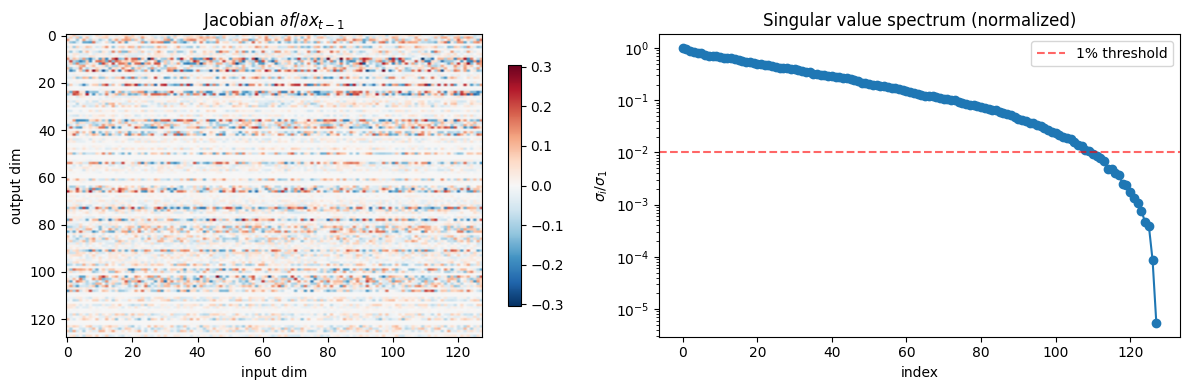

In [13]:
typical_state  = seq_trajectory[100]
typical_driver = drivers[101]
J = jax.jacfwd(deer_fxn)(typical_state, typical_driver)

U, sv, Vt = jnp.linalg.svd(J)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

im = axes[0].imshow(J, aspect='auto', cmap='RdBu_r',
                    vmin=-jnp.abs(J).max(), vmax=jnp.abs(J).max())
axes[0].set_title(r'Jacobian $\partial f / \partial x_{t-1}$')
axes[0].set_xlabel('input dim'); axes[0].set_ylabel('output dim')
plt.colorbar(im, ax=axes[0], shrink=0.8)

axes[1].semilogy(sv / sv[0], 'o-', markersize=6)
axes[1].axhline(0.01, color='red', ls='--', alpha=0.6, label='1% threshold')
axes[1].set_xlabel('index'); axes[1].set_ylabel(r'$\sigma_i / \sigma_1$')
axes[1].set_title('Singular value spectrum (normalized)')
axes[1].legend()

eff_rank = int((sv / sv[0] > 0.01).sum())
print(f"Spectral radius: {sv[0]:.4f}")
print(f"Effective rank (>1% of sigma_1): {eff_rank}")
print(f"Singular values: {sv}")

plt.tight_layout()

## Baseline convergence: DEER, quasi-DEER, Jacobi, Picard

In [14]:
max_n = 100
iters = list(range(1, max_n + 1))

# DEER baselines — use mf_val (7th return value) directly
*_, deer_errs   = deer_alg(deer_fxn, initial_state, states_guess, drivers, max_n, full_trace=True)
*_, quasi_errs  = deer_alg(deer_fxn, initial_state, states_guess, drivers, max_n, quasi=True, full_trace=True)
*_, jacobi_errs = jacobi_alg(deer_fxn, initial_state, states_guess, drivers, max_n, full_trace=True)
*_, picard_errs = picard_alg(deer_fxn, initial_state, states_guess, drivers, max_n, full_trace=True)

deer_errs   = list(np.array(deer_errs))
quasi_errs  = list(np.array(quasi_errs))
jacobi_errs = list(np.array(jacobi_errs))
picard_errs = list(np.array(picard_errs))

In [15]:
# Iterations to convergence
for name, alg, kwargs in [
    ("DEER",       deer_alg, {}),
    ("quasi-DEER", deer_alg, dict(quasi=True)),
    ("Jacobi",     jacobi_alg, {}),
    ("Picard",     picard_alg, {}),
]:
    _, _, nb_iters, *_ = alg(deer_fxn, initial_state, states_guess, drivers,
                              num_iters=max_n, tol=5e-4, **kwargs)
    nb = int(nb_iters) if nb_iters is not None else max_n
    print(f"{name}: converged in {nb} iterations")

DEER: converged in 7 iterations
quasi-DEER: converged in 27 iterations
Jacobi: converged in 27 iterations
Picard: converged in 100 iterations


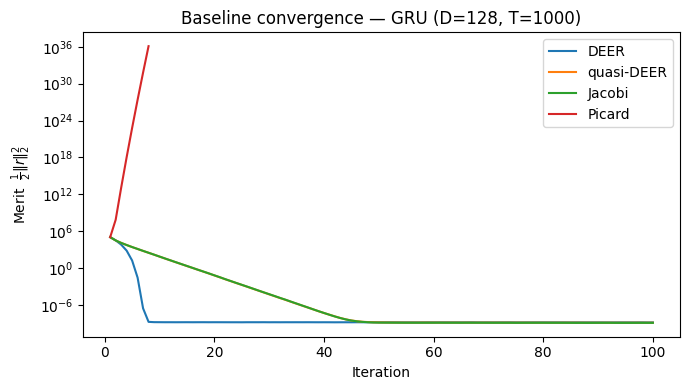

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.semilogy(iters, deer_errs,   label="DEER")
ax.semilogy(iters, quasi_errs,  label="quasi-DEER")
ax.semilogy(iters, jacobi_errs, label="Jacobi")
ax.semilogy(iters, picard_errs, label="Picard")

ax.set_xlabel("Iteration")
ax.set_ylabel(r"Merit  $\frac{1}{2}\|r\|_2^2$")
ax.set_title(f"Baseline convergence — GRU (D={D}, T={T})")
ax.legend()
plt.tight_layout()

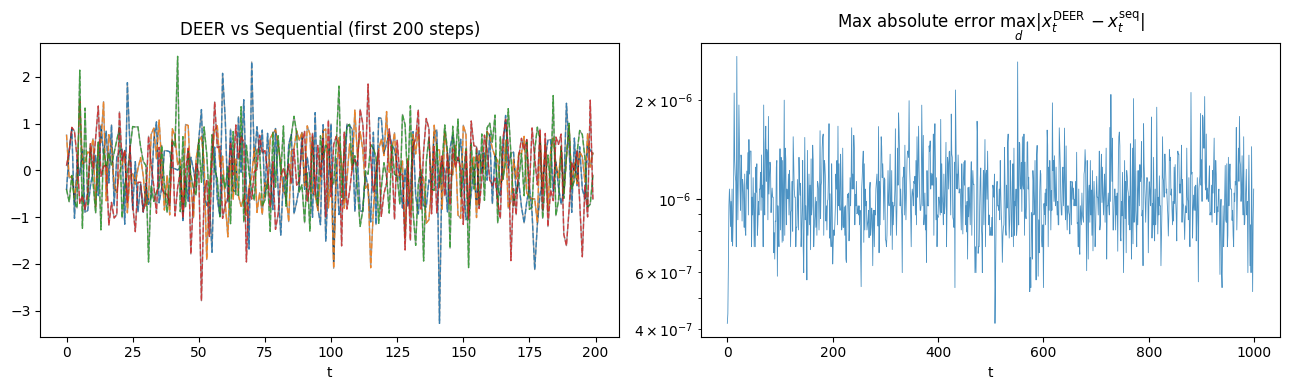

In [17]:
# Compare converged trajectories to sequential
_, deer_final, *_ = deer_alg(deer_fxn, initial_state, states_guess, drivers, num_iters=max_n, tol=5e-4)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for d in range(min(D, 4)):
    axes[0].plot(seq_trajectory[:200, d], 'k-', alpha=0.4, linewidth=1)
    axes[0].plot(deer_final[:200, d], '--', alpha=0.8, linewidth=1)
axes[0].set_title('DEER vs Sequential (first 200 steps)')
axes[0].set_xlabel('t')

err = jnp.abs(deer_final - seq_trajectory)
axes[1].semilogy(jnp.max(err, axis=1), alpha=0.8, linewidth=0.6)
axes[1].set_title(r'Max absolute error $\max_d |x^{\mathrm{DEER}}_t - x^{\mathrm{seq}}_t|$')
axes[1].set_xlabel('t')
plt.tight_layout()

## Broyden-DEER convergence

Merit function vs Newton iterations for all Broyden init schemes at various window sizes `m`.

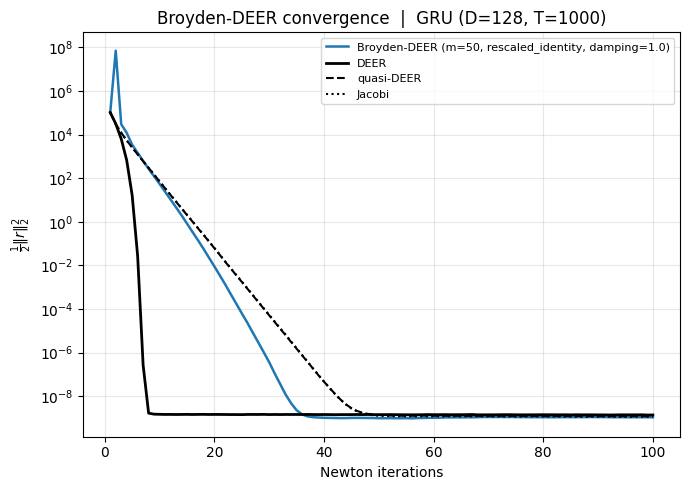

In [20]:
bd_m = 50
bd_init = "rescaled_identity"
bd_damping = 1.0

*_, bd_errs = broyden_deer_alg(
    deer_fxn, initial_state, states_guess, drivers, max_n,
    m=bd_m, init=bd_init, damping=bd_damping, full_trace=True)
bd_errs = list(np.array(bd_errs))

fig, ax = plt.subplots(figsize=(7, 5))

ax.semilogy(iters, bd_errs, "-", color="tab:blue", linewidth=1.8,
            label=f"Broyden-DEER (m={bd_m}, {bd_init}, damping={bd_damping})")
ax.semilogy(iters, deer_errs,   "k-",  linewidth=2,   label="DEER")
ax.semilogy(iters, quasi_errs,  "k--", linewidth=1.5, label="quasi-DEER")
ax.semilogy(iters, jacobi_errs, "k:",  linewidth=1.5, label="Jacobi")
ax.set_xlabel("Newton iterations")
ax.set_ylabel(r"$\frac{1}{2}\|r\|_2^2$")
ax.set_title(f"Broyden-DEER convergence  |  GRU (D={D}, T={T})")
ax.legend(fontsize=8); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()

## Accelerated Broyden convergence

In [ ]:
acc_k = 3
acc_damping = 1.0
acc_init = "rescaled_identity"

*_, acc_errs = accelerated_broyden_deer_alg(
    deer_fxn, initial_state, states_guess, drivers, max_n,
    k=acc_k, init=acc_init, damping=acc_damping, full_trace=True)
acc_errs = list(np.array(acc_errs))

fig, ax = plt.subplots(figsize=(7, 5))

ax.semilogy(iters, acc_errs, "-", color="tab:purple", linewidth=1.8,
            label=f"Accel. Broyden (k={acc_k}, damping={acc_damping}, {acc_init})")
ax.semilogy(iters, deer_errs,   "k-",  linewidth=2,   label="DEER")
ax.semilogy(iters, quasi_errs,  "k--", linewidth=1.5, label="quasi-DEER")
ax.semilogy(iters, jacobi_errs, "k:",  linewidth=1.5, label="Jacobi")
ax.set_xlabel("Newton iterations")
ax.set_ylabel(r"$\frac{1}{2}\|r\|_2^2$")
ax.set_title(f"Accelerated Broyden convergence  |  GRU (D={D}, T={T})")
ax.legend(fontsize=8); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()

## Full-Broyden (global Woodbury) convergence

Merit function vs Newton iterations for all init schemes at various ranks `k`.

In [ ]:
fb_k = 3
fb_init = "rescaled_identity"
fb_damping = 1.0

*_, fb_errs = full_broyden_deer_alg(
    deer_fxn, initial_state, states_guess, drivers, max_n,
    k=fb_k, init=fb_init, damping=fb_damping, full_trace=True)
fb_errs = list(np.array(fb_errs))

fig, ax = plt.subplots(figsize=(7, 5))

ax.semilogy(iters, fb_errs, "-", color="tab:cyan", linewidth=1.8,
            label=f"Full-Broyden (k={fb_k}, {fb_init}, damping={fb_damping})")
ax.semilogy(iters, deer_errs,   "k-",  linewidth=2,   label="DEER")
ax.semilogy(iters, quasi_errs,  "k--", linewidth=1.5, label="quasi-DEER")
ax.semilogy(iters, jacobi_errs, "k:",  linewidth=1.5, label="Jacobi")
ax.set_xlabel("Newton iterations")
ax.set_ylabel(r"$\frac{1}{2}\|r\|_2^2$")
ax.set_title(f"Full-Broyden convergence  |  GRU (D={D}, T={T})")
ax.legend(fontsize=8); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()